# 04 · Modelado: pronóstico de la demanda

**Entrada:** `data/processed/consumo_horario.parquet` · **Funciones:** `src/features.py` y `src/modeling.py`
**Parámetros:** `src/config.py` (`HORIZONTE_HORAS`, `REZAGOS_HORAS`, `VENTANAS_HORAS`, `FECHA_CORTE`, `N_PLIEGUES`, `MESES_PLIEGUE`, `SEMILLA`)

**Salida:** `data/processed/residuos_PJME.parquet` (residuos fuera de muestra, entrada del notebook 06) y `metricas_ventana_movil_PJME.parquet`.

Este pronóstico es la **referencia de lo esperable**: lo que interesa es cuánto y cuándo se desvía la demanda real, no solo la precisión.

**Diseño del experimento**

| Elemento | Decisión |
|---|---|
| Objetivo | Consumo horario (`MW`) de una región |
| Horizonte | 24 horas: para predecir la hora *t* solo se usa información hasta *t − 24* |
| Calendario | Día operativo: las variables se calculan desde `Datetime − 1 h` (ver `01_exploracion.ipynb`, sección 2.1) |
| División | Cronológica: entrenamiento antes de `FECHA_CORTE`, prueba desde esa fecha |
| Validación | Ventana móvil con entrenamiento creciente: bloques consecutivos de `MESES_PLIEGUE` meses, al menos `N_PLIEGUES` pliegues |
| Modelo base | El consumo de ayer a la misma hora |
| Modelo | XGBoost con variables de calendario, rezagos y medias móviles |
| Métricas | MAE y RMSE (en MW), MAPE (en %) y MASE (frente al pronóstico ingenuo de ayer a la misma hora) |

**Contenido**
1. Configuración y carga
2. Variables
3. División en entrenamiento y prueba
4. Modelo base
5. XGBoost
6. Evaluación (partición única y ventana móvil)
7. Análisis de errores
8. Resumen y limitaciones

## 1. Configuración y carga

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    PROCESSED_DIR, HORIZONTE_HORAS, REZAGOS_HORAS, VENTANAS_HORAS,
    FECHA_CORTE, N_PLIEGUES, MESES_PLIEGUE,
)
from src.features import agregar_variables_temporales, agregar_rezagos, agregar_medias_moviles
from src.modeling import (
    seleccionar_variables,
    dividir_train_test,
    construir_X_y,
    pronostico_base,
    entrenar_xgboost,
    predecir,
    comparar_modelos,
    importancia_variables,
    validar_ventana_movil,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

REGION = 'PJME'    # región a pronosticar

In [2]:
df = pd.read_parquet(PROCESSED_DIR / "consumo_horario.parquet")
df = df[df['region'] == REGION]

print(f"{REGION}: {len(df):,} filas · {df['Datetime'].min():%Y-%m-%d} → {df['Datetime'].max():%Y-%m-%d}")
print(f"Horizonte: {HORIZONTE_HORAS} h · rezagos: {REZAGOS_HORAS} · ventanas: {VENTANAS_HORAS} · corte: {FECHA_CORTE}")

PJME: 145,392 filas · 2002-01-01 → 2018-08-03
Horizonte: 24 h · rezagos: [24, 48, 168] · ventanas: [24, 168] · corte: 2017-01-01


## 2. Variables

- **Calendario:** hora, día de la semana, mes, fin de semana y festivo, calculados con el **día operativo** (`Datetime − 1 h`; la hora va de 0 a 23). Se conocen de antemano.
- **Rezagos:** consumo de hace 24, 48 y 168 horas.
- **Medias móviles:** promedio de las 24 y 168 horas previas, desplazado 24 horas.

Todas las variables de historia respetan el horizonte: ninguna usa información posterior a *t − 24*.

In [3]:
df = agregar_variables_temporales(df)
df = agregar_rezagos(df)
df = agregar_medias_moviles(df)

variables = seleccionar_variables(df)
print("Variables del modelo:", variables)
print(f"Rezago mínimo: {min(REZAGOS_HORAS)} h (horizonte: {HORIZONTE_HORAS} h)")
df[['Datetime', 'fecha', 'MW'] + variables].head()

Variables del modelo: ['hora', 'dia_semana', 'mes', 'es_fin_de_semana', 'es_festivo', 'MW_lag_24', 'MW_lag_48', 'MW_lag_168', 'MW_media_24h', 'MW_media_168h']
Rezago mínimo: 24 h (horizonte: 24 h)


,Datetime,fecha,MW,hora,dia_semana,mes,es_fin_de_semana,es_festivo,MW_lag_24,MW_lag_48,MW_lag_168,MW_media_24h,MW_media_168h
0,2002-01-01 01:00:00,2002-01-01,30393.0,0,1,1,False,True,NaN,NaN,NaN,NaN,NaN
1,2002-01-01 02:00:00,2002-01-01,29265.0,1,1,1,False,True,NaN,NaN,NaN,NaN,NaN
2,2002-01-01 03:00:00,2002-01-01,28357.0,2,1,1,False,True,NaN,NaN,NaN,NaN,NaN
3,2002-01-01 04:00:00,2002-01-01,27899.0,3,1,1,False,True,NaN,NaN,NaN,NaN,NaN
4,2002-01-01 05:00:00,2002-01-01,28057.0,4,1,1,False,True,NaN,NaN,NaN,NaN,NaN


## 3. División en entrenamiento y prueba

La división es por fecha, nunca al azar: el modelo se entrena con el pasado y se evalúa con un futuro que no ha visto. Los rezagos se calcularon antes de dividir, así que las primeras horas de la prueba usan el final del entrenamiento (información que sí existiría en la práctica). Con la hora-fin, la prueba empieza en `2017-01-01 00:00`, que es la hora 23 del 2016-12-31: ese primer día operativo queda incompleto y se excluye de los análisis diarios (sección 7.4).

In [4]:
train, test = dividir_train_test(df)

X_train, y_train = construir_X_y(train)
X_test, y_test = construir_X_y(test)

print(f"X_train: {X_train.shape} · X_test: {X_test.shape}")

Entrenamiento: 131,495 filas (2002-01-01 → 2016-12-31)
Prueba:        13,897 filas (2017-01-01 → 2018-08-03)
Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0
X_train: (131304, 10) · X_test: (13897, 10)


## 4. Modelo base

Referencias sencillas que cualquier modelo debe superar: el consumo de ayer a la misma hora (24 h) y el de la semana anterior (168 h).

In [5]:
base_24h = pronostico_base(test, rezago=24).loc[X_test.index]
base_168h = pronostico_base(test, rezago=168).loc[X_test.index]

comparar_modelos(
    y_test, {'Base 24 h': base_24h, 'Base 168 h': base_168h}, real_train=train['MW']
).round(2)

,MAE,RMSE,MAPE_%,MASE
Base 24 h,2300.08,3134.18,7.32,1.06
Base 168 h,3511.18,4793.98,10.99,1.63


## 5. XGBoost

Se entrena con los valores por defecto de `entrenar_xgboost` (500 árboles, tasa de aprendizaje 0.05, profundidad 6). Los parámetros se pueden sobrescribir al llamar a la función.

In [6]:
modelo = entrenar_xgboost(X_train, y_train)
pred_xgb = predecir(modelo, X_test)

pred_xgb.head()

131495    29933.714844
131496    27649.357422
131497    27354.111328
131498    26812.207031
131499    26444.121094
Name: prediccion, dtype: float32

## 6. Evaluación

**MASE** compara el MAE con el error del pronóstico ingenuo de «ayer a la misma hora» medido en el entrenamiento: menor que 1 significa que el modelo se equivoca menos que ese pronóstico, y permite comparar regiones de distinto tamaño. Se calcula con la escala de 24 h incluso para el modelo base de 168 h.

### Partición única (corte en `FECHA_CORTE`)

In [7]:
metricas = comparar_modelos(y_test, {
    'Base 24 h': base_24h,
    'Base 168 h': base_168h,
    'XGBoost': pred_xgb,
}, real_train=train['MW'])
metricas.round(2)

,MAE,RMSE,MAPE_%,MASE
Base 24 h,2300.08,3134.18,7.32,1.06
Base 168 h,3511.18,4793.98,10.99,1.63
XGBoost,1861.58,2512.52,5.89,0.86


In [8]:
mejora = (1 - metricas.loc['XGBoost', 'MAE'] / metricas.loc['Base 24 h', 'MAE']) * 100
print(f"XGBoost reduce el MAE un {mejora:.1f} % respecto al modelo base de 24 h")
print(f"MASE de XGBoost: {metricas.loc['XGBoost', 'MASE']:.2f} (menor que 1: mejor que el pronóstico ingenuo)")

XGBoost reduce el MAE un 19.1 % respecto al modelo base de 24 h
MASE de XGBoost: 0.86 (menor que 1: mejor que el pronóstico ingenuo)


### Real frente a pronóstico

Ventana de dos semanas alrededor del mayor pico de consumo del periodo de prueba.

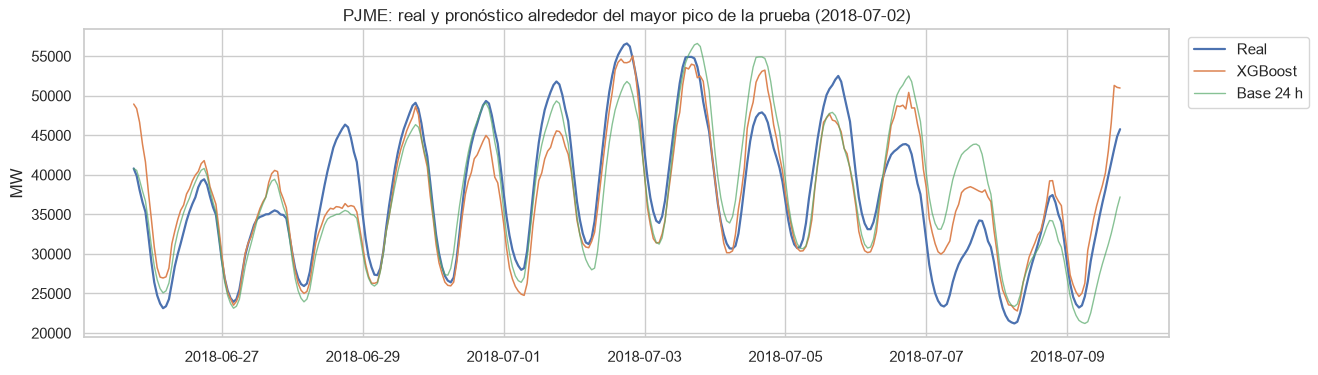

In [9]:
resultados = (
    test.loc[X_test.index, ['Datetime', 'fecha', 'MW', 'hora', 'mes', 'es_festivo', 'es_fin_de_semana']]
    .assign(xgboost=pred_xgb, base_24h=base_24h)
)
resultados['error_xgboost'] = (resultados['xgboost'] - resultados['MW']).abs()
resultados['error_base_24h'] = (resultados['base_24h'] - resultados['MW']).abs()

fecha_pico = resultados.loc[resultados['MW'].idxmax(), 'Datetime']
ventana = resultados[resultados['Datetime'].between(
    fecha_pico - pd.Timedelta(days=7), fecha_pico + pd.Timedelta(days=7))]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ventana['Datetime'], ventana['MW'], label='Real', linewidth=1.6)
ax.plot(ventana['Datetime'], ventana['xgboost'], label='XGBoost', linewidth=1.1)
ax.plot(ventana['Datetime'], ventana['base_24h'], label='Base 24 h', linewidth=1, alpha=0.7)
ax.set_title(f'{REGION}: real y pronóstico alrededor del mayor pico de la prueba ({fecha_pico:%Y-%m-%d})')
ax.set_ylabel('MW')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

### Validación en ventana móvil

Con una sola partición el resultado depende del periodo de prueba. Aquí el entrenamiento y la prueba se repiten en bloques consecutivos de `MESES_PLIEGUE` meses que terminan en la última fecha. Cada pliegue entrena con todo lo anterior y prueba en su bloque, así que los bloques no se solapan y cada hora se predice **una sola vez, fuera de muestra**.

Se usan 6 pliegues (el criterio mínimo es `N_PLIEGUES`) para que los residuos cubran **2012-08 → 2018-08**, que incluye episodios que el notebook 06 contrasta (huracán Sandy, vórtice polar de 2014, ola de frío de 2015). **Criterio de cierre:** XGBoost supera al modelo base en todos los pliegues.

**Convención del residuo:** `residuo = real − predicción`. Positivo significa demanda por encima de lo esperable.

In [10]:
PLIEGUES = 6    # >= N_PLIEGUES; con 6 pliegues de 12 meses los residuos cubren 2012-08 → 2018-08
assert PLIEGUES >= N_PLIEGUES

metricas_vm, residuos = validar_ventana_movil(df, n_pliegues=PLIEGUES)

tabla_vm = metricas_vm.reset_index()
tabla_vm['pliegue'] = tabla_vm['pliegue'].astype(int)
tabla_vm[['pliegue', 'modelo', 'inicio_prueba', 'fin_prueba', 'MAE', 'RMSE', 'MAPE_%', 'MASE', 'mejora_MAE_%']].round(2)

Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0
Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0
Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0
Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0
Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0
Filas descartadas por vacíos en las variables: 191
Filas descartadas por vacíos en las variables: 0
El modelo supera al base en todos los pliegues: True


C:\Users\lukas\AppData\Local\Temp\ipykernel_13876\3809073429.py:8: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  tabla_vm[['pliegue', 'modelo', 'inicio_prueba', 'fin_prueba', 'MAE', 'RMSE', 'MAPE_%', 'MASE', 'mejora_MAE_%']].round(2)


,pliegue,modelo,inicio_prueba,fin_prueba,MAE,RMSE,MAPE_%,MASE,mejora_MAE_%
0,1,XGBoost,2012-08-03,2013-08-03,1551.19,2141.29,4.84,0.72,-24.29
1,1,Base,2012-08-03,2013-08-03,2048.83,2813.22,6.47,0.95,NaN
2,2,XGBoost,2013-08-03,2014-08-03,1723.19,2378.22,5.32,0.80,-28.26
3,2,Base,2013-08-03,2014-08-03,2401.88,3275.42,7.48,1.12,NaN
4,3,XGBoost,2014-08-03,2015-08-03,1688.23,2314.50,5.17,0.78,-25.03
5,3,Base,2014-08-03,2015-08-03,2251.80,3021.51,6.96,1.04,NaN
6,4,XGBoost,2015-08-03,2016-08-03,1580.75,2155.47,5.06,0.73,-21.49
7,4,Base,2015-08-03,2016-08-03,2013.47,2810.94,6.43,0.93,NaN
8,5,XGBoost,2016-08-03,2017-08-03,1727.46,2367.62,5.44,0.80,-20.54
9,5,Base,2016-08-03,2017-08-03,2174.01,2985.13,6.92,1.00,NaN


XGBoost supera al base en todos los pliegues: True
MASE de XGBoost menor que 1 en todos los pliegues: True


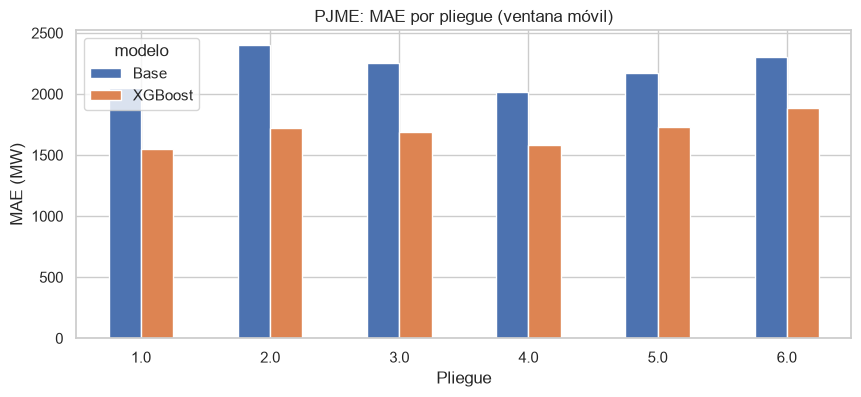

In [11]:
mae_vm = metricas_vm['MAE'].unstack('modelo')
mase_vm = metricas_vm['MASE'].unstack('modelo')
print("XGBoost supera al base en todos los pliegues:", bool((mae_vm['XGBoost'] < mae_vm['Base']).all()))
print("MASE de XGBoost menor que 1 en todos los pliegues:", bool((mase_vm['XGBoost'] < 1).all()))

ax = mae_vm.plot.bar(figsize=(10, 4), rot=0, title=f'{REGION}: MAE por pliegue (ventana móvil)')
ax.set_xlabel('Pliegue')
ax.set_ylabel('MAE (MW)')
plt.show()

### Residuos fuera de muestra

Se guardan para el notebook 06 (días atípicos) y para la página de pronóstico del panel.

In [12]:
print(f"Residuos: {len(residuos):,} horas · {residuos['Datetime'].min():%Y-%m-%d} → {residuos['Datetime'].max():%Y-%m-%d}")
print("Cada hora aparece una sola vez:", residuos['Datetime'].is_unique)

residuos.to_parquet(PROCESSED_DIR / f"residuos_{REGION}.parquet", index=False)
metricas_vm.reset_index().to_parquet(PROCESSED_DIR / f"metricas_ventana_movil_{REGION}.parquet", index=False)
residuos.head()

Residuos: 52,584 horas · 2012-08-03 → 2018-08-03
Cada hora aparece una sola vez: True


,Datetime,real,prediccion,residuo,pliegue
92808,2012-08-03 01:00:00,34983.0,31643.828125,3339.171875,1
92809,2012-08-03 02:00:00,32651.0,29446.089844,3204.910156,1
92810,2012-08-03 03:00:00,31038.0,28166.806641,2871.193359,1
92811,2012-08-03 04:00:00,30123.0,27566.251953,2556.748047,1
92812,2012-08-03 05:00:00,30089.0,27493.123047,2595.876953,1


## 7. Análisis de errores

Error absoluto medio (MAE, en MW) del modelo base y de XGBoost según la hora, el mes y el tipo de día.

### 7.1 Por hora del día

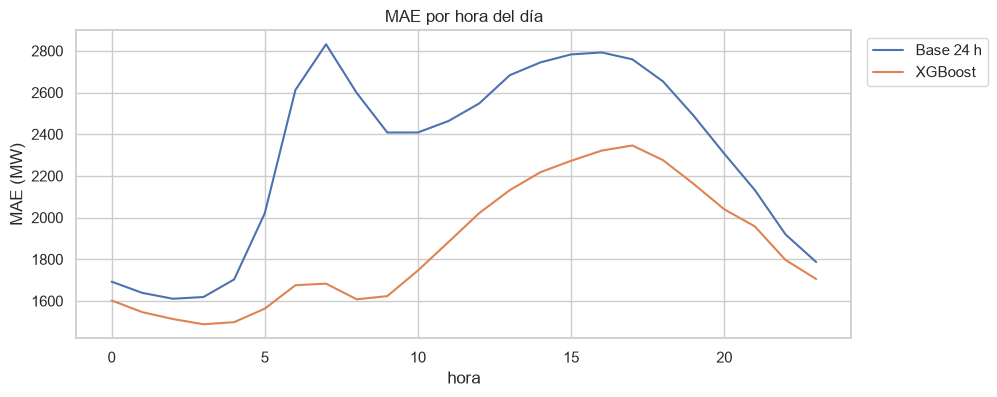

In [13]:
mae_hora = resultados.groupby('hora')[['error_base_24h', 'error_xgboost']].mean()
mae_hora.columns = ['Base 24 h', 'XGBoost']

ax = mae_hora.plot(figsize=(10, 4), title='MAE por hora del día')
ax.set_ylabel('MAE (MW)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

### 7.2 Por mes

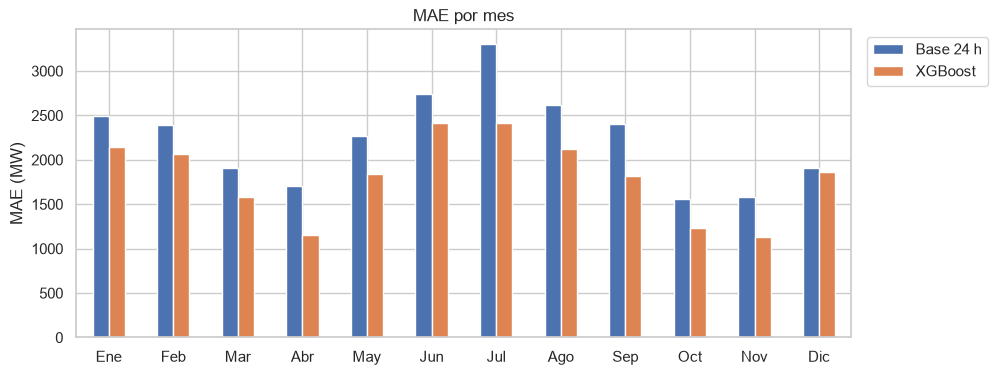

In [14]:
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

mae_mes = resultados.groupby('mes')[['error_base_24h', 'error_xgboost']].mean()
mae_mes.index = [MESES[m - 1] for m in mae_mes.index]
mae_mes.columns = ['Base 24 h', 'XGBoost']

ax = mae_mes.plot.bar(figsize=(10, 4), title='MAE por mes', rot=0)
ax.set_ylabel('MAE (MW)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

### 7.3 Por tipo de día

In [15]:
resultados['tipo_dia'] = np.select(
    [resultados['es_festivo'], resultados['es_fin_de_semana']],
    ['Festivo', 'Fin de semana'],
    default='Laborable',
)

(resultados.groupby('tipo_dia')[['error_base_24h', 'error_xgboost']].mean()
 .rename(columns={'error_base_24h': 'MAE Base 24 h', 'error_xgboost': 'MAE XGBoost'})
 .join(resultados['tipo_dia'].value_counts().rename('horas'))
 .round(1))

,MAE Base 24 h,MAE XGBoost,horas
tipo_dia,,,
Festivo,2701.2,1886.9,408
Fin de semana,2554.5,1906.9,3913
Laborable,2179.0,1842.0,9576


### 7.4 Los 10 días con mayor error

Los días son días operativos (`fecha`). Solo se consideran días completos (24 horas): el primer día de la prueba empieza en su hora 23 y su error no es comparable.

In [16]:
por_dia = (resultados.groupby('fecha')
           .agg(MAE_xgboost=('error_xgboost', 'mean'),
                MAE_base_24h=('error_base_24h', 'mean'),
                festivo=('es_festivo', 'first'),
                horas=('MW', 'size')))

peores = por_dia[por_dia['horas'] == 24].nlargest(10, 'MAE_xgboost').drop(columns='horas')
peores.index = peores.index.strftime('%Y-%m-%d')
peores.round(1)

,MAE_xgboost,MAE_base_24h,festivo
fecha,,,
2017-05-20,8097.7,12062.3,False
2018-06-03,6665.2,7405.4,False
2018-07-07,6161.3,10061.4,False
2017-07-29,5671.2,6826.7,False
2017-03-15,5143.6,3515.7,False
2017-09-28,5032.7,5605.8,False
2017-12-31,5000.1,1858.7,False
2018-05-29,4949.0,7582.1,False
2017-07-25,4938.2,4091.5,False


### 7.5 Importancia de las variables

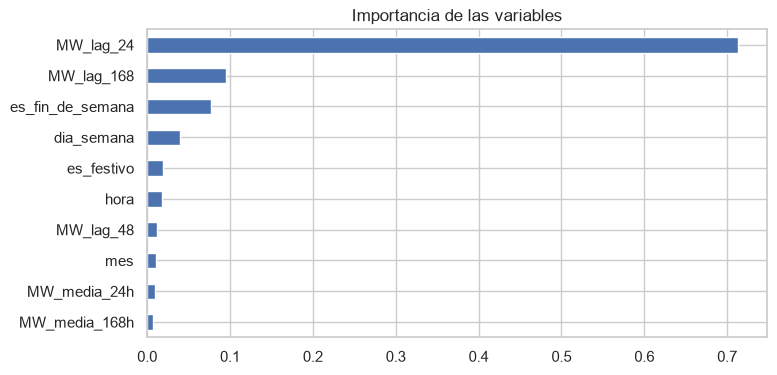

,importancia
MW_lag_24,0.713
MW_lag_168,0.095
es_fin_de_semana,0.077
dia_semana,0.040
es_festivo,0.019
hora,0.018
MW_lag_48,0.012
mes,0.011
MW_media_24h,0.009
MW_media_168h,0.006


In [17]:
importancia = importancia_variables(modelo, list(X_train.columns))

importancia.sort_values('importancia').plot.barh(figsize=(8, 4), legend=False, title='Importancia de las variables')
plt.show()

importancia.round(3)

## 8. Resumen y limitaciones

> Los campos `[completar]` se rellenan con los resultados de las secciones 6 y 7 al ejecutar el notebook con los datos reales. Las cifras anteriores (MAE de 1,862 MW frente a 2,300 MW) se calcularon con la hora-fin y deben reemplazarse por las nuevas.

### Diseño aplicado

| Elemento | Valor |
|---|---|
| Región | `PJME` |
| Horizonte | 24 horas |
| Calendario | Día operativo (`Datetime − 1 h`) |
| Entrenamiento (partición única) | `[completar]` |
| Prueba (partición única) | `[completar]` |
| Validación en ventana móvil | 6 pliegues de 12 meses, entrenamiento creciente, prueba `[completar]` |
| Variables | Calendario (hora, día de la semana, mes, fin de semana, festivo), rezagos de 24, 48 y 168 h y medias móviles de 24 y 168 h |
| Modelo base | Consumo de hace 24 horas |
| Algoritmo | XGBoost (500 árboles, tasa de aprendizaje 0.05, profundidad 6, `SEMILLA = 42`) |

### Resultados (partición única)

| Modelo | MAE (MW) | RMSE (MW) | MAPE (%) | MASE |
|---|---|---|---|---|
| Base 24 h | `[completar]` | `[completar]` | `[completar]` | `[completar]` |
| Base 168 h | `[completar]` | `[completar]` | `[completar]` | `[completar]` |
| XGBoost | `[completar]` | `[completar]` | `[completar]` | `[completar]` |

### Resultados (ventana móvil)

| Pliegue | Prueba | MAE XGBoost (MW) | MAE base (MW) | Mejora (%) | MASE XGBoost |
|---|---|---|---|---|---|
| 1 a 6 | `[completar]` | `[completar]` | `[completar]` | `[completar]` | `[completar]` |

**¿XGBoost supera al base en todos los pliegues?** `[completar]`

**Interpretación:** `[completar]`

### Limitaciones

- **Sin temperatura.** Es el principal determinante de la demanda y el dataset no la incluye. Las variables de calendario y el historial de consumo no pueden anticipar olas de calor o frío, por lo que los picos extremos son los más difíciles de pronosticar. Eso hace que un residuo grande pueda ser clima y no una anomalía de otro tipo.
- **Ventana móvil con bloques de 12 meses.** Reduce la dependencia de un solo periodo, pero cada pliegue sigue siendo un año concreto con su clima. Los primeros pliegues entrenan con menos historia que los últimos.
- **Una región.** El modelo y los residuos son de `PJME`; el análisis de días atípicos de otras regiones exige repetir el proceso con cada una.
- **Festivos federales.** Los festivos usados son los federales de EE. UU.; los de cada estado no están incluidos.
- **Parámetros por defecto.** XGBoost no se ha ajustado con búsqueda de hiperparámetros.

**Siguiente paso:** `05_agrupamiento.ipynb` (tipos de día) y `06_anomalias.ipynb`, que usa `residuos_PJME.parquet`.